# FloodNet — evaluación final y figuras del paper

Este cuaderno **no entrena nada**. Carga los tres modelos ya entrenados por los otros cuadernos y
saca lo que el paper necesita y que no estaba guardado:

- la **matriz de confusión por píxel en test** de los tres modelos, con el mismo formato
  (`conf[ground truth, predicho]`, 10 clases);
- el **mIoU del U-Net sin TTA**, para separar lo que aporta el TTA;
- **todas las figuras del paper**, en inglés y con un estilo común, en `paper/figures/`.

Antes de usar nada comprueba (sección 3) que cada modelo **reproduce el mIoU de test que ya
publicaron sus cuadernos**: U-Net 0.7315, DeepLabV3+ 0.7094 y YOLO11n-seg 0.6607. Si alguno no
coincide, se para con un `assert`.

| Modelo | Checkpoint | Inferencia (la misma de su cuaderno) |
|---|---|---|
| U-Net híbrido | `models/best_model_iou_full.pth` | fp32, TTA de 4 volteos (y una pasada sin TTA) |
| DeepLabV3+ R50 | `models/deeplabv3plus_r50_full_best.pt` | fp32, sin TTA |
| YOLO11n-seg | `runs/yolo/yolo11n-seg-full/weights/best.pt` | conf 0.25, NMS 0.7, instancias de mayor a menor área, sin cubrir = *Background* |

Salidas, todas en `paper/` y sin tocar `models/`, `runs/` ni `data/`:

| Fichero | Qué es |
|---|---|
| `paper/confusion_test.npz` | Conteos de píxeles (int64) de las cuatro matrices: `unet`, `unet_noTTA`, `deeplab`, `yolo` |
| `paper/test_metrics.json` | mIoU, Dice y pixel accuracy con y sin *Background*, e IoU por clase |
| `paper/figures/flood_*.png` | Figuras del paper |

## 1. Entorno, rutas y partición

In [1]:
import json
import sys
import time
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import timm
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

PROJECT  = Path.cwd()
DATA     = PROJECT / "data"
CACHE    = DATA / "cache512_full"
FLOODNET = DATA / "FloodNet" / "FloodNet-Supervised_v1.0"
OUT      = PROJECT / "paper"
FIG      = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)

UNET_CKPT    = PROJECT / "models" / "best_model_iou_full.pth"
DEEPLAB_CKPT = PROJECT / "models" / "deeplabv3plus_r50_full_best.pt"
YOLO_CKPT    = PROJECT / "runs" / "yolo" / "yolo11n-seg-full" / "weights" / "best.pt"
EXCEL        = PROJECT / "floodnet_resultados.xlsx"
for p in (CACHE / "index.csv", UNET_CKPT, DEEPLAB_CKPT, YOLO_CKPT, EXCEL):
    assert p.exists(), f"No encuentro {p}"

NUM_CLASSES = 10
CLASS_NAMES = ["Background", "Building-flooded", "Building-non-flooded", "Road-flooded",
               "Road-non-flooded", "Water", "Tree", "Vehicle", "Pool", "Grass"]
SIZE = 512
MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
STD  = np.array([0.229, 0.224, 0.225], dtype=np.float32)

# mIoU de test (10 clases) que publicaron los cuadernos de entrenamiento.
PUBLICADO = {"unet": 0.7315, "deeplab": 0.7094, "yolo": 0.6607}

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Python", sys.version.split()[0], "· torch", torch.__version__, "· device", device)

Python 3.12.10 · torch 2.14.0+cu126 · device cuda


In [2]:
# Misma regla que los tres cuadernos: fuera las máscaras OFICIALES de una sola clase,
# partición oficial intacta.
idx = pd.read_csv(CACHE / "index.csv", dtype={"stem": str, "clases": str})
excluidas = idx[(idx["n_clases"] == 1) & (idx["mascara"] == "oficial")]
usadas = idx.drop(excluidas.index)
tam = tuple(int((usadas["split"] == s).sum()) for s in ("train", "val", "test"))
assert tam == (1387, 434, 426), f"El split no coincide con el de los cuadernos: {tam}"
test_stems = sorted(usadas.loc[usadas["split"] == "test", "stem"])
print("Partición:", dict(zip(("train", "val", "test"), tam)), "· excluidas:", len(excluidas))

def leer_rgb(stem):
    return cv2.cvtColor(cv2.imread(str(CACHE / "image" / f"{stem}.png")), cv2.COLOR_BGR2RGB)

def leer_mascara(stem):
    return cv2.imread(str(CACHE / "mask" / f"{stem}.png"), cv2.IMREAD_GRAYSCALE)

def a_tensor(rgb):
    # Igual que A.Normalize(mean, std) + ToTensorV2 de los cuadernos.
    return torch.from_numpy(((rgb.astype(np.float32) / 255.0 - MEAN) / STD).transpose(2, 0, 1))

def confusion(pred, gt):
    pred, gt = pred.reshape(-1).astype(np.int64), gt.reshape(-1).astype(np.int64)
    ok = (gt >= 0) & (gt < NUM_CLASSES)
    return np.bincount(gt[ok] * NUM_CLASSES + pred[ok],
                       minlength=NUM_CLASSES ** 2).reshape(NUM_CLASSES, NUM_CLASSES)

def resumen(conf):
    # Mismas definiciones que SegMetrics: matriz acumulada y una sola división al final.
    c = conf.astype(np.float64)
    tp, gt, pr = np.diag(c), c.sum(1), c.sum(0)
    with np.errstate(invalid="ignore", divide="ignore"):
        iou = np.where(gt + pr - tp > 0, tp / (gt + pr - tp), np.nan)
        dice = np.where(gt + pr > 0, 2 * tp / (gt + pr), np.nan)
    return {"mIoU": float(np.nanmean(iou)), "mIoU_sin_bg": float(np.nanmean(iou[1:])),
            "Dice": float(np.nanmean(dice)), "Dice_sin_bg": float(np.nanmean(dice[1:])),
            "PixAcc": float(tp.sum() / c.sum()),
            "IoU_por_clase": dict(zip(CLASS_NAMES, map(float, iou)))}

Partición: {'train': 1387, 'val': 434, 'test': 426} · excluidas: 96


## 2. Inferencia sobre las 426 imágenes de test

### 2.1 U-Net híbrido

Misma definición que la sección 4 de `floodnet-segmentation.ipynb`. El backbone se crea con
`pretrained=False` porque todos los pesos salen del checkpoint, y `load_state_dict` es estricto: si la
definición no coincidiera con la entrenada, fallaría aquí. Se guardan dos matrices: con el TTA de 4
volteos del cuaderno (la cifra publicada) y con una sola pasada.

In [3]:
class AttentionGate(nn.Module):
    def __init__(self, g_channels, x_channels, inter_channels):
        super().__init__()
        self.w_g = nn.Conv2d(g_channels, inter_channels, kernel_size=1)
        self.w_x = nn.Conv2d(x_channels, inter_channels, kernel_size=1)
        self.psi = nn.Conv2d(inter_channels, 1, kernel_size=1)
        self.relu = nn.ReLU(inplace=True)
        self.sigmoid = nn.Sigmoid()

    def forward(self, g, x):
        return x * self.sigmoid(self.psi(self.relu(self.w_g(g) + self.w_x(x))))

class ASPP(nn.Module):
    def __init__(self, in_channels, out_channels=512, rates=(1, 6, 12, 18)):
        super().__init__()
        self.aspp1 = nn.Conv2d(in_channels, out_channels, 1)
        self.aspp2 = nn.Conv2d(in_channels, out_channels, 3, padding=rates[1], dilation=rates[1])
        self.aspp3 = nn.Conv2d(in_channels, out_channels, 3, padding=rates[2], dilation=rates[2])
        self.aspp4 = nn.Conv2d(in_channels, out_channels, 3, padding=rates[3], dilation=rates[3])
        self.global_pool = nn.Sequential(nn.AdaptiveAvgPool2d(1),
                                         nn.Conv2d(in_channels, out_channels, 1), nn.ReLU(inplace=True))
        self.out_conv = nn.Conv2d(out_channels * 5, out_channels, 1)
        self.bn = nn.BatchNorm2d(out_channels)
        self.relu = nn.ReLU(inplace=True)

    def forward(self, x):
        f5 = F.interpolate(self.global_pool(x), size=x.shape[2:], mode="bilinear", align_corners=False)
        out = torch.cat([self.aspp1(x), self.aspp2(x), self.aspp3(x), self.aspp4(x), f5], dim=1)
        return self.relu(self.bn(self.out_conv(out)))

class TransformerBlock(nn.Module):
    def __init__(self, dim, heads=8, mlp_ratio=4.0):
        super().__init__()
        self.norm1 = nn.LayerNorm(dim)
        self.attn = nn.MultiheadAttention(embed_dim=dim, num_heads=heads, batch_first=True)
        self.norm2 = nn.LayerNorm(dim)
        self.mlp = nn.Sequential(nn.Linear(dim, int(dim * mlp_ratio)), nn.GELU(),
                                 nn.Linear(int(dim * mlp_ratio), dim))

    def forward(self, x):
        x = x + self.attn(self.norm1(x), self.norm1(x), self.norm1(x))[0]
        return x + self.mlp(self.norm2(x))

class DecoderBlock(nn.Module):
    def __init__(self, in_channels, skip_channels, out_channels):
        super().__init__()
        self.up = nn.Sequential(nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False),
                                nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
                                nn.BatchNorm2d(out_channels), nn.ReLU(inplace=True))
        self.att_gate = (AttentionGate(out_channels, skip_channels, out_channels // 2)
                         if skip_channels > 0 else None)
        total_in = out_channels + skip_channels if skip_channels > 0 else out_channels
        self.conv = nn.Sequential(nn.Conv2d(total_in, out_channels, 3, padding=1),
                                  nn.BatchNorm2d(out_channels), nn.ReLU(inplace=True),
                                  nn.Conv2d(out_channels, out_channels, 3, padding=1),
                                  nn.BatchNorm2d(out_channels), nn.ReLU(inplace=True))

    def forward(self, x, skip=None):
        x = self.up(x)
        if skip is not None and self.att_gate is not None:
            skip = self.att_gate(x, F.interpolate(skip, size=x.shape[2:], mode="bilinear", align_corners=False))
        if skip is not None:
            x = torch.cat([x, skip], dim=1)
        return self.conv(x)

class HybridEncoder(nn.Module):
    def __init__(self, patch_size=4, dim=512, depth=12, backbone_name="convnext_tiny"):
        super().__init__()
        self.backbone = timm.create_model(backbone_name, pretrained=False, features_only=True)
        self.patch_in_ch = 768
        self.skip_channels = [96, 192, 384, 768]
        self.patch_embed = nn.Conv2d(self.patch_in_ch, dim, kernel_size=patch_size, stride=patch_size)
        self.pos_embedding = nn.Parameter(torch.randn(1, (32 // 2) ** 2, dim))
        self.blocks = nn.ModuleList([TransformerBlock(dim) for _ in range(depth)])

    def forward(self, x):
        x1, x2, x3, x4 = self.backbone(x)[:4]
        p = self.patch_embed(x4)
        _, _, h, w = p.shape
        tokens = p.flatten(2).transpose(1, 2) + self.pos_embedding[:, :h * w, :]
        for blk in self.blocks:
            tokens = blk(tokens)
        return tokens, x1, x2, x3, x4, h, w

class ViT_UNet(nn.Module):
    def __init__(self, num_classes=10, dim=512, backbone_name="convnext_tiny"):
        super().__init__()
        self.encoder = HybridEncoder(patch_size=4, dim=dim, depth=12, backbone_name=backbone_name)
        skip_ch = self.encoder.skip_channels
        self.aspp = ASPP(dim, dim)
        self.dec1 = DecoderBlock(dim, skip_ch[3], 256)
        self.dec2 = DecoderBlock(256, skip_ch[2], 128)
        self.dec3 = DecoderBlock(128, skip_ch[1], 64)
        self.dec4 = DecoderBlock(64, skip_ch[0], 32)
        self.dec5 = DecoderBlock(32, 0, 32)
        self.head = nn.Conv2d(32, num_classes, 1)
        self.aux_head2 = nn.Conv2d(128, num_classes, 1)   # solo en entrenamiento
        self.aux_head3 = nn.Conv2d(64, num_classes, 1)    # solo en entrenamiento

    def forward(self, x):
        tokens, x1, x2, x3, x4, H, W = self.encoder(x)
        B, N, C = tokens.shape
        feat = self.aspp(tokens.transpose(1, 2).reshape(B, C, H, W))
        f2 = self.dec2(self.dec1(feat, x4), x3)
        f3 = self.dec3(f2, x2)
        f5 = self.dec5(self.dec4(f3, x1), None)
        return F.interpolate(self.head(f5), size=(SIZE, SIZE), mode="bilinear", align_corners=False)

In [4]:
t0 = time.time()
unet = ViT_UNet().to(device)
unet.load_state_dict(torch.load(UNET_CKPT, map_location=device))
unet.eval()
print(f"U-Net: {sum(p.numel() for p in unet.parameters()):,} parámetros")

conf_unet = np.zeros((NUM_CLASSES, NUM_CLASSES), np.int64)
conf_unet_sin_tta = np.zeros_like(conf_unet)
pred = {"unet": {}, "unet_noTTA": {}, "deeplab": {}, "yolo": {}}
with torch.no_grad():
    for i in range(0, len(test_stems), 4):                  # lotes de 4, como el cuaderno
        lote = test_stems[i:i + 4]
        x = torch.stack([a_tensor(leer_rgb(s)) for s in lote]).to(device)
        salidas = []
        for dims in ((), (3,), (2,), (2, 3)):               # original y volteos h, v, hv
            o = unet(torch.flip(x, dims) if dims else x)
            salidas.append(torch.flip(o, dims) if dims else o)
        p_sin = salidas[0].argmax(1).cpu().numpy()
        p_tta = torch.stack([torch.softmax(o, 1) for o in salidas]).mean(0).argmax(1).cpu().numpy()
        for s, a, b in zip(lote, p_tta, p_sin):
            gt = leer_mascara(s)
            conf_unet += confusion(a, gt)
            conf_unet_sin_tta += confusion(b, gt)
            pred["unet"][s], pred["unet_noTTA"][s] = a.astype(np.uint8), b.astype(np.uint8)
del unet
if device.type == "cuda":
    torch.cuda.empty_cache()
print(f"U-Net: {time.time() - t0:.0f} s")

U-Net: 86,680,082 parámetros
U-Net: 63 s


### 2.2 DeepLabV3+ (ResNet-50)

In [5]:
import segmentation_models_pytorch as smp

t0 = time.time()
deeplab = smp.DeepLabV3Plus(encoder_name="resnet50", encoder_weights=None,
                            encoder_output_stride=16, classes=NUM_CLASSES).to(device)
deeplab.load_state_dict(torch.load(DEEPLAB_CKPT, map_location=device))
deeplab.eval()
conf_deeplab = np.zeros((NUM_CLASSES, NUM_CLASSES), np.int64)
with torch.no_grad():
    for i in range(0, len(test_stems), 8):
        lote = test_stems[i:i + 8]
        x = torch.stack([a_tensor(leer_rgb(s)) for s in lote]).to(device)
        for s, p in zip(lote, deeplab(x).argmax(1).cpu().numpy()):
            conf_deeplab += confusion(p, leer_mascara(s))
            pred["deeplab"][s] = p.astype(np.uint8)
del deeplab
if device.type == "cuda":
    torch.cuda.empty_cache()
print(f"DeepLabV3+: {time.time() - t0:.0f} s")

DeepLabV3+: 14 s


### 2.3 YOLO11n-seg

Mismo paso de instancias a mapa semántico que `mapa_semantico()` en la sección 6.2 de
`floodnet-yolo11n-seg.ipynb`: se pintan de mayor a menor área, de modo que las pequeñas quedan
encima, y lo que no cubre ninguna instancia es *Background*.

In [6]:
from ultralytics import YOLO

t0 = time.time()
yolo = YOLO(str(YOLO_CKPT))
conf_yolo = np.zeros((NUM_CLASSES, NUM_CLASSES), np.int64)
for s in test_stems:
    r = yolo.predict(str(CACHE / "image" / f"{s}.png"), imgsz=SIZE, conf=0.25, iou=0.7, max_det=300,
                     retina_masks=True, device=0 if device.type == "cuda" else "cpu", verbose=False)[0]
    lab = np.zeros((SIZE, SIZE), np.uint8)
    if r.masks is not None and len(r.masks):
        m = r.masks.data.cpu().numpy() > 0.5
        if m.shape[1:] != (SIZE, SIZE):
            m = np.stack([cv2.resize(x.astype(np.uint8), (SIZE, SIZE), interpolation=cv2.INTER_NEAREST) > 0
                          for x in m])
        cls = r.boxes.cls.cpu().numpy().astype(int) + 1       # clase YOLO k = clase FloodNet k + 1
        for j in np.argsort(-m.sum(axis=(1, 2)), kind="stable"):
            lab[m[j]] = cls[j]
    conf_yolo += confusion(lab, leer_mascara(s))
    pred["yolo"][s] = lab
print(f"YOLO11n-seg: {time.time() - t0:.0f} s")

YOLO11n-seg: 14 s


## 3. Comprobación frente a las cifras publicadas y guardado

La tolerancia es de 0.0005: los cuadernos publican cuatro decimales y la GPU puede variar el último
píxel de algún empate de `argmax`. Si no se cumple, el cuaderno se para aquí y no se guarda nada.

In [7]:
confs = {"unet": conf_unet, "unet_noTTA": conf_unet_sin_tta, "deeplab": conf_deeplab, "yolo": conf_yolo}
metricas = {k: resumen(c) for k, c in confs.items()}

print(f"{'modelo':12s} {'mIoU':>7s} {'publicado':>10s} {'sin BG':>7s} {'Dice':>7s} {'PixAcc':>7s}")
for k, m in metricas.items():
    ref = PUBLICADO.get(k)
    print(f"{k:12s} {m['mIoU']:7.4f} {ref if ref else '':>10} {m['mIoU_sin_bg']:7.4f} "
          f"{m['Dice']:7.4f} {m['PixAcc']:7.4f}")
for k, ref in PUBLICADO.items():
    assert abs(metricas[k]["mIoU"] - ref) < 5e-4, f"{k} no reproduce su cifra publicada"
print("\nLos tres modelos reproducen el mIoU publicado.")

np.savez(OUT / "confusion_test.npz", class_names=np.array(CLASS_NAMES), **confs)
metricas["_info"] = {"imagenes_test": len(test_stems), "device": str(device), "torch": torch.__version__,
                     "nota": "conf[ground_truth, predicho], pixeles a 512x512"}
(OUT / "test_metrics.json").write_text(json.dumps(metricas, indent=2, ensure_ascii=False), encoding="utf-8")
print("Guardado:", OUT / "confusion_test.npz", "y", OUT / "test_metrics.json")

modelo          mIoU  publicado  sin BG    Dice  PixAcc
unet          0.7315     0.7315  0.7543  0.8406  0.9099
unet_noTTA    0.7276             0.7502  0.8378  0.9088
deeplab       0.7093     0.7094  0.7381  0.8227  0.9077
yolo          0.6607     0.6607  0.7302  0.7632  0.8832

Los tres modelos reproducen el mIoU publicado.
Guardado: c:\Users\javmi\Desktop\Proyectos_Vision\FloodNet\paper\confusion_test.npz y c:\Users\javmi\Desktop\Proyectos_Vision\FloodNet\paper\test_metrics.json


## 4. Figuras del paper

Estilo común para todas: paleta de FloodNet de los cuadernos, nombres de clase en inglés, tipografía
Times y ancho de texto de LNCS (12,2 cm).

In [8]:
PALETA = np.array([[0, 0, 0], [255, 0, 0], [180, 120, 120], [160, 150, 20], [140, 140, 140],
                   [61, 230, 250], [0, 82, 255], [255, 0, 245], [255, 235, 0], [4, 250, 7]], dtype=np.uint8)
ANCHO = 4.8   # pulgadas, ancho de texto LNCS
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Liberation Serif", "TeX Gyre Termes", "DejaVu Serif"],
    "mathtext.fontset": "stix", "font.size": 8, "axes.titlesize": 8, "axes.labelsize": 8,
    "xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 7, "axes.linewidth": 0.6,
    "savefig.dpi": 300, "savefig.bbox": "tight", "savefig.pad_inches": 0.02,
})

def colorear(lab):
    return PALETA[np.clip(lab, 0, 9)]

def leyenda(fig, clases, ncol, y):
    fig.legend(handles=[Patch(facecolor=PALETA[c] / 255, edgecolor="0.3", linewidth=0.4, label=CLASS_NAMES[c])
                        for c in clases],
               loc="lower center", ncol=ncol, frameon=False, bbox_to_anchor=(0.5, y),
               handlelength=1.2, columnspacing=1.0, handletextpad=0.4)

### 4.1 Fig. 1 — máscara oficial frente a la revisada

Dos imágenes de train en las que el error de la máscara oficial no deja lugar a dudas (de
`revision_mascaras/`): 7774, un prado entero marcado como *Water*, y 9022, matorral marcado como
*Background*. La revisada es la de la caché, que en estas imágenes es la de Kaggle.

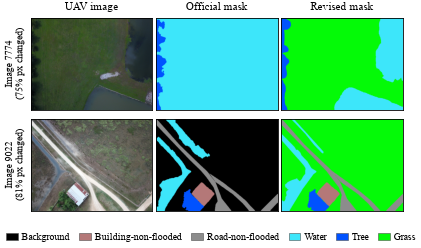

In [9]:
EJEMPLOS = ["7774", "9022"]
W, H = 512, 384                                       # se muestran con el 4:3 original
fig, axes = plt.subplots(len(EJEMPLOS), 3, figsize=(ANCHO, 2.55), gridspec_kw={"wspace": 0.03, "hspace": 0.06})
presentes = set()
for i, s in enumerate(EJEMPLOS):
    assert idx.set_index("stem").loc[s, "mascara"] == "reparada"
    img = leer_rgb(s)
    rev = leer_mascara(s)
    ofi = cv2.imread(str(FLOODNET / "train" / "train-label-img" / f"{s}_lab.png"), cv2.IMREAD_GRAYSCALE)
    ofi = cv2.resize(ofi, rev.shape[::-1], interpolation=cv2.INTER_NEAREST)
    presentes |= set(np.unique(ofi).tolist()) | set(np.unique(rev).tolist())
    for j, t in enumerate([cv2.resize(img, (W, H), interpolation=cv2.INTER_AREA),
                           cv2.resize(colorear(ofi), (W, H), interpolation=cv2.INTER_NEAREST),
                           cv2.resize(colorear(rev), (W, H), interpolation=cv2.INTER_NEAREST)]):
        axes[i, j].imshow(t); axes[i, j].set_xticks([]); axes[i, j].set_yticks([])
    axes[i, 0].set_ylabel(f"Image {s}\n({100 * (ofi != rev).mean():.0f}% px changed)", fontsize=7)
for j, t in enumerate(["UAV image", "Official mask", "Revised mask"]):
    axes[0, j].set_title(t, fontsize=8)
leyenda(fig, sorted(presentes), ncol=6, y=-0.04)
fig.savefig(FIG / "flood_mask_revision.png"); plt.show()

### 4.2 Fig. 2 — representación de cada clase en train

Datos de la hoja *Distribución de clases* de `floodnet_resultados.xlsx`, que genera la sección 6.5 de
`floodnet-segmentation.ipynb`.

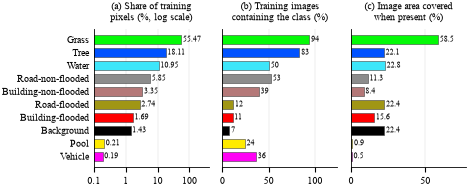

In [10]:
dist = pd.read_excel(EXCEL, sheet_name="Distribución de clases", header=None, skiprows=5, nrows=10,
                     usecols=[0, 2, 7, 9], names=["clase", "px", "img", "ocupa"]).set_index("clase")
assert set(dist.index) == set(CLASS_NAMES)
dist = 100 * dist.sort_values("px")
y = np.arange(NUM_CLASSES)
colores = [PALETA[CLASS_NAMES.index(c)] / 255 for c in dist.index]
fig, axes = plt.subplots(1, 3, figsize=(ANCHO, 1.8), sharey=True, gridspec_kw={"wspace": 0.12})
paneles = [("px", "Share of training\npixels (%, log scale)", True, "{:.2f}"),
           ("img", "Training images\ncontaining the class (%)", False, "{:.0f}"),
           ("ocupa", "Image area covered\nwhen present (%)", False, "{:.1f}")]
for ax, letra, (col, titulo, log, fmt) in zip(axes, "abc", paneles):
    v = dist[col].to_numpy()
    ax.barh(y, v, color=colores, edgecolor="0.25", linewidth=0.4, height=0.72)
    if log:
        ax.set_xscale("log"); ax.set_xlim(0.1, 400)
        ax.set_xticks([0.1, 1, 10, 100], ["0.1", "1", "10", "100"]); ax.minorticks_off()
    else:
        ax.set_xlim(0, v.max() * 1.32)
    for yi, vi in zip(y, v):
        ax.text(vi * 1.12 if log else vi + v.max() * 0.02, yi, fmt.format(vi), va="center", fontsize=6)
    ax.set_title(f"({letra}) {titulo}", fontsize=7.5)
    ax.tick_params(axis="y", length=0); ax.grid(axis="x", linewidth=0.3, alpha=0.5); ax.set_axisbelow(True)
    for lado in ("top", "right"):
        ax.spines[lado].set_visible(False)
axes[0].set_yticks(y, dist.index)
fig.savefig(FIG / "flood_class_representation.png"); plt.show()

### 4.3 Fig. 3 — matrices de confusión de test

Las tres con el mismo formato: *ground truth* en filas, predicción en columnas, normalizadas por fila
(% de los píxeles reales de cada clase), misma escala de color y mismas clases en el mismo orden.

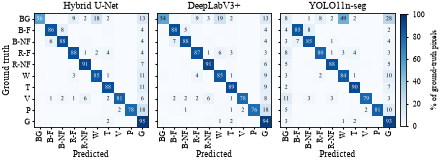


== unet (% por fila) ==
        BG   B-F  B-NF   R-F  R-NF     W     T     V     P     G
BG    56.2   0.5   0.2   8.5   1.7  18.5   1.6   0.1   0.0  12.8
B-F    0.5  86.0   7.8   0.2   0.0   0.4   0.8   0.1   0.0   4.3
B-NF   0.1   6.3  88.3   0.0   0.8   0.1   0.6   0.0   0.0   3.7
R-F    0.3   0.3   0.0  87.8   1.3   2.5   3.5   0.3   0.0   4.0
R-NF   0.1   0.0   0.4   0.1  91.2   0.0   0.8   0.2   0.0   7.3
W      0.5   0.2   0.1   2.8   0.1  84.5   1.1   0.0   0.0  10.7
T      0.1   0.1   0.1   0.6   0.3   0.4  87.6   0.0   0.0  10.8
V      0.4   1.2   2.4   1.2   5.6   0.1   1.8  81.0   0.0   6.4
P      0.2   0.2   0.3   0.2   0.1   0.2   0.9   1.6  78.1  18.3
G      0.1   0.2   0.3   0.3   0.8   0.9   2.0   0.0   0.0  95.5

== deeplab (% por fila) ==
        BG   B-F  B-NF   R-F  R-NF     W     T     V     P     G
BG    53.8   0.5   0.3   8.9   2.5  18.8   1.7   0.2   0.1  13.3
B-F    0.6  88.2   5.0   0.6   0.0   0.6   0.6   0.1   0.0   4.3
B-NF   0.1   6.7  87.6   0.0   0.8   

In [11]:
ABREV = ["BG", "B-F", "B-NF", "R-F", "R-NF", "W", "T", "V", "P", "G"]
fig, axes = plt.subplots(1, 3, figsize=(ANCHO, 1.95), gridspec_kw={"wspace": 0.08})
for ax, (k, titulo) in zip(axes, [("unet", "Hybrid U-Net"), ("deeplab", "DeepLabV3+"), ("yolo", "YOLO11n-seg")]):
    c = confs[k].astype(np.float64)
    cn = 100 * c / np.maximum(c.sum(1, keepdims=True), 1)
    im = ax.imshow(cn, cmap="Blues", vmin=0, vmax=100)
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            if cn[i, j] >= 1:
                ax.text(j, i, f"{cn[i, j]:.0f}", ha="center", va="center", fontsize=4.6,
                        color="white" if cn[i, j] > 55 else "black")
    ax.set_xticks(range(NUM_CLASSES), ABREV, rotation=90, fontsize=5.5)
    ax.set_yticks(range(NUM_CLASSES), ABREV if ax is axes[0] else [""] * NUM_CLASSES, fontsize=5.5)
    ax.tick_params(length=1.5, pad=1)
    ax.set_title(titulo, fontsize=7.5, pad=3); ax.set_xlabel("Predicted", fontsize=6.5, labelpad=1)
axes[0].set_ylabel("Ground truth", fontsize=6.5, labelpad=1)
cb = fig.colorbar(im, ax=axes, fraction=0.015, pad=0.015)
cb.ax.tick_params(labelsize=5.5, length=1.5); cb.set_label("% of ground-truth pixels", fontsize=6)
fig.savefig(FIG / "flood_confusion_test.png"); plt.show()

# Tabla con los porcentajes, para redactar el texto del paper.
for k in ("unet", "deeplab", "yolo"):
    c = confs[k].astype(np.float64)
    print(f"\n== {k} (% por fila) ==")
    print(pd.DataFrame(100 * c / c.sum(1, keepdims=True), index=ABREV, columns=ABREV).round(1).to_string())

### 4.4 Fig. 4 — ejemplos cualitativos de test

Las imágenes se eligen con una regla fija, no a ojo: la imagen de test con más píxeles de
*Road-flooded*, la que tiene más de *Building-flooded* y la que tiene más de *Vehicle*, es decir, las
clases que más importan para planificar rutas y la clase pequeña más difícil.

Imágenes elegidas: ['7457', '7420', '6927']


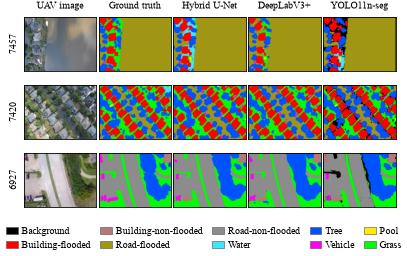

In [12]:
px = {s: np.bincount(leer_mascara(s).ravel(), minlength=NUM_CLASSES) for s in test_stems}
elegidas = []
for c in (3, 1, 7):                       # Road-flooded, Building-flooded, Vehicle
    s = max((s for s in test_stems if s not in elegidas), key=lambda s: px[s][c])
    elegidas.append(s)
print("Imágenes elegidas:", elegidas)

columnas = [("UAV image", None), ("Ground truth", None), ("Hybrid U-Net", "unet"),
            ("DeepLabV3+", "deeplab"), ("YOLO11n-seg", "yolo")]
fig, axes = plt.subplots(len(elegidas), len(columnas), figsize=(ANCHO, 2.6),
                         gridspec_kw={"wspace": 0.03, "hspace": 0.05})
presentes = set()
for i, s in enumerate(elegidas):
    gt = leer_mascara(s)
    tiles = [cv2.resize(leer_rgb(s), (W, H), interpolation=cv2.INTER_AREA), colorear(gt)]
    tiles += [colorear(pred[k][s]) for _, k in columnas[2:]]
    for k in [gt] + [pred[k][s] for _, k in columnas[2:]]:
        presentes |= set(np.unique(k).tolist())
    for j, t in enumerate(tiles):
        axes[i, j].imshow(cv2.resize(t, (W, H), interpolation=cv2.INTER_NEAREST) if j else t)
        axes[i, j].set_xticks([]); axes[i, j].set_yticks([])
    axes[i, 0].set_ylabel(s, fontsize=7)
for j, (t, _) in enumerate(columnas):
    axes[0, j].set_title(t, fontsize=7.5)
leyenda(fig, sorted(presentes), ncol=5, y=-0.07)
fig.savefig(FIG / "flood_qualitative_test.png"); plt.show()

## 5. Resumen

Cifras que este cuaderno añade al paper (el resto sale de las salidas de los otros tres cuadernos y
de `floodnet_resultados.xlsx`; ver `docs/trazabilidad_paper.md`).

In [13]:
print(f"mIoU U-Net con TTA : {metricas['unet']['mIoU']:.4f}")
print(f"mIoU U-Net sin TTA : {metricas['unet_noTTA']['mIoU']:.4f}  "
      f"(sin Background: {metricas['unet_noTTA']['mIoU_sin_bg']:.4f})")
print("Figuras:", sorted(p.name for p in FIG.glob("flood_*.png")))

mIoU U-Net con TTA : 0.7315
mIoU U-Net sin TTA : 0.7276  (sin Background: 0.7502)
Figuras: ['flood_class_representation.png', 'flood_confusion_test.png', 'flood_mask_revision.png', 'flood_qualitative_test.png']
